# Mock simulation basics with `meer21cm`

*Runtime: about 12 s on a MacBook (Apple M2), full notebook.*

A first look at the `MockSimulation` class. We

* set up a plain cubic box and simulate a lognormal matter field and an HI brightness temperature field in it;
* see how the class is used: you read and set attributes, and quantities are computed only when you first ask for them;
* see how `meer21cm` stores (caches) results, and recomputes only what depends on an input you change;
* measure the power spectrum of the HI field and compare it with the input model.

## 1. Set up

Everything lives in one object. Inputs are passed when creating it, and can be read or changed later as ordinary attributes.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from meer21cm import MockSimulation
from meer21cm.util import redshift_to_freq

plt.rcParams.update({"font.size": 13})

mock = MockSimulation(
    nu=redshift_to_freq(np.array([0.51, 0.49])),  # observed frequencies [Hz]: two channels, 21cm line at z = 0.51 and 0.49 (centre z = 0.5)
    tracer_bias_1=1.5,                     # linear bias of tracer 1 (HI)
    mean_amp_1="average_hi_temp",          # tracer 1 is in K: density contrast times the mean HI temperature
    kaiser_rsd=False,                      # no redshift-space distortions, to keep the model simple
    seed=42,                               # random seed, for reproducible mocks
)
print(f"z = {mock.z:.2f}")
print(f"Omega_HI = {mock.omega_hi[0]:.1e}")
print(f"mean HI temperature = {mock.average_hi_temp * 1e3:.4f} mK")
print(f"HI bias = {mock.tracer_bias_1}")

z = 0.50
Omega_HI = 5.0e-04
mean HI temperature = 0.1090 mK
HI bias = 1.5


## 2. A plain cubic box

Normally the box is derived from the survey (sky area and frequency range). Here we simply set it by hand: a cube of 1000 Mpc per side with $200^3$ cells (5 Mpc cells). The box sets the range of scales: from the fundamental mode $k_{\rm f} = 2\pi/L$ to the Nyquist frequency $k_{\rm Ny} = \pi/\Delta x$.

In [2]:
mock.box_len = np.array([1000.0, 1000.0, 1000.0])  # side lengths of the box [Mpc]
mock.box_ndim = np.array([200, 200, 200])           # number of cells along each side

cell = mock.box_len / mock.box_ndim
print(f"cell size: {cell[0]:.0f} Mpc")
print(f"k_f = {2 * np.pi / mock.box_len[0]:.4f} Mpc^-1,  k_Ny = {np.pi / cell[0]:.3f} Mpc^-1")

cell size: 5 Mpc
k_f = 0.0063 Mpc^-1,  k_Ny = 0.628 Mpc^-1


## 3. Quantities are computed when you first ask for them

Nothing has been simulated yet. Asking for `mock.matter_power_spectrum_fnc` (the matter power spectrum $P_{\rm m}(k)$ at $z$, computed with CAMB) or `mock.mock_matter_field` (a lognormal matter density field drawn from it) triggers the calculation. The result is stored, so asking again is instant.

In [3]:
%time pk_m = mock.matter_power_spectrum_fnc   # first access: runs CAMB
%time delta_m = mock.mock_matter_field        # first access: draws the lognormal field (P_m is reused)
%time delta_m_again = mock.mock_matter_field  # second access: stored result

print("same array:", delta_m_again is delta_m)
print("shape:", delta_m.shape, f" rms density contrast: {delta_m.std():.2f}")

CPU times: user 2.73 s, sys: 15.6 ms, total: 2.75 s
Wall time: 404 ms


CPU times: user 454 ms, sys: 128 ms, total: 581 ms
Wall time: 584 ms
CPU times: user 1 μs, sys: 0 ns, total: 1 μs
Wall time: 2.15 μs
same array: True
shape: (200, 200, 200)  rms density contrast: 1.54


The HI field `mock.mock_tracer_field_1` is a separate lognormal field, drawn from $b_{\rm HI}^2 P_{\rm m}(k)$ with the same random seed, and multiplied by the mean HI temperature. Only the field generation is needed: $P_{\rm m}$ is already stored.

In [4]:
%time t_hi = mock.mock_tracer_field_1         # first access: draws the HI field
%time t_hi_again = mock.mock_tracer_field_1   # second access: stored field, times the mean temperature
print(f"HI field rms: {t_hi.std() * 1e3:.3f} mK")
print("same array:", t_hi_again is t_hi)

CPU times: user 443 ms, sys: 101 ms, total: 543 ms
Wall time: 563 ms
CPU times: user 3.4 ms, sys: 1.93 ms, total: 5.32 ms
Wall time: 5.2 ms
HI field rms: 0.252 mK
same array: False


The stored HI field is the dimensionless one; each access multiplies it by $\bar{T}_{\rm HI}$, so you get a new array every time (hence "same array: False" above), but nothing is simulated again: the second access only takes the few milliseconds of the multiplication.

## 4. Changing an input recomputes only what depends on it

Each stored quantity carries a list of inputs it depends on. You can look these up in `mock.dependency_dict`:

In [5]:
for name in ["matter_power_spectrum_fnc", "mock_matter_field", "mock_tracer_field_1"]:
    print(f"{name:26s}", mock.dependency_dict[name])

matter_power_spectrum_fnc  ('cosmo_model', 'nu')
mock_matter_field          ('cosmo_model', 'nu', 'mock', 'box', 'rsd', 'seed')
mock_tracer_field_1        ('cosmo_model', 'nu', 'mock', 'box', 'tracer_1', 'rsd', 'seed')


Setting an input clears every stored quantity that depends on it. The HI bias belongs to the group `tracer_1`; these are the stored quantities it clears:

In [6]:
print(mock.tracer_1_dep_attr)

['_auto_power_tracer_1_model', '_auto_power_tracer_1_model_noobs', '_cross_power_tracer_model', '_cross_power_tracer_model_noobs', '_mock_kaiser_field_k_tracer_1', '_mock_tracer_field_1', '_mock_tracer_field_1_r', '_mock_tracer_position_in_box', '_mock_tracer_position_in_radecz', '_mock_velocity_u_tracer_1']


**Change the HI bias.** The matter field does not depend on it, so it is kept (same array, instant). The HI field is cleared and drawn again from the new $b_{\rm HI}^2 P_{\rm m}$. The seed is fixed, so it is the same realisation with a larger amplitude.

In [7]:
mock.tracer_bias_1 = 2.0  # new HI bias

%time delta_m_after_bias = mock.mock_matter_field  # kept
print("matter field unchanged:", delta_m_after_bias is delta_m)

%time t_hi_new = mock.mock_tracer_field_1          # drawn again
print(f"HI rms: {t_hi.std() * 1e3:.3f} mK -> {t_hi_new.std() * 1e3:.3f} mK "
      f"(ratio {t_hi_new.std() / t_hi.std():.2f}; bias ratio {2.0 / 1.5:.2f})")

CPU times: user 2 μs, sys: 1 μs, total: 3 μs
Wall time: 3.1 μs
matter field unchanged: True


CPU times: user 438 ms, sys: 105 ms, total: 544 ms
Wall time: 546 ms
HI rms: 0.252 mK -> 0.337 mK (ratio 1.34; bias ratio 1.33)


The rms grows by about the bias ratio (not exactly, because the lognormal transform is not linear).

**Change the cosmology.** Raising the amplitude of the primordial power spectrum $A_s$ by 20% changes $P_{\rm m}(k)$, so CAMB runs again and the matter field is drawn again (same seed, so the same structures with about $\sqrt{1.2} \approx 1.10$ times the amplitude).

In [8]:
mock.As = 1.2 * mock.As  # amplitude of the primordial power spectrum, raised by 20%

%time delta_m_new = mock.mock_matter_field  # CAMB runs again, then a new field
print("matter field unchanged:", delta_m_new is delta_m)
print(f"rms density contrast: {delta_m.std():.2f} -> {delta_m_new.std():.2f}")

CPU times: user 3.17 s, sys: 112 ms, total: 3.29 s
Wall time: 950 ms
matter field unchanged: False
rms density contrast: 1.54 -> 1.69


**Change the box.** Setting the box clears the fields (even if the values are the same), but $P_{\rm m}(k)$ does not depend on the box and is kept: only the field is drawn again.

In [9]:
mock.box_ndim = np.array([200, 200, 200])  # set the box again (same values)

%time delta_m_box = mock.mock_matter_field  # field drawn again, P_m reused
print("matter field unchanged:", delta_m_box is delta_m_new)

CPU times: user 440 ms, sys: 94.8 ms, total: 535 ms
Wall time: 540 ms
matter field unchanged: False


## 5. Power spectrum

The mock is also a power spectrum estimator. We pass the HI field as `field_1`, choose 1D $k$ bins (45 linear bins of width $1.5\,k_{\rm f}$), and `get_1d_power` averages the 3D power `auto_power_3d_1` in spherical shells. The input model comes from the same machinery: `auto_power_tracer_1_model` is the model power on the same 3D $k$-grid, here $\bar{T}_{\rm HI}^2\, b_{\rm HI}^2\, P_{\rm m}(k)$ with the current values ($b_{\rm HI} = 2$, raised $A_s$). There is no RSD (`kaiser_rsd=False`), no beam and no survey window in this simple box, so no observational effects enter the model. `get_1d_power` averages it in the same $k$ shells as the measurement, so the two are compared bin by bin.

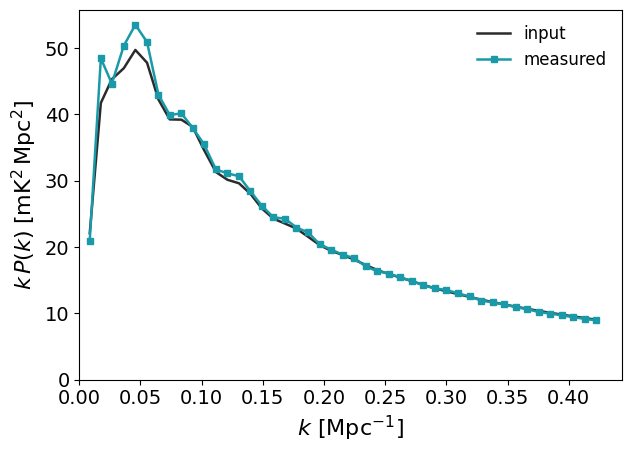

modes in the lowest 5 bins: [ 17  90 169 386 485]
measured / input: 0.95 to 1.16


In [10]:
mock.field_1 = mock.mock_tracer_field_1          # field to measure [K]
k_f = 2 * np.pi / mock.box_len[0]               # fundamental mode [Mpc^-1]
mock.k1dbins = k_f * (0.5 + 1.5 * np.arange(46))  # edges of 45 linear k bins [Mpc^-1], width 1.5 k_f, up to 0.43 Mpc^-1 (below k_Ny)
p_meas, k_meas, nmodes = mock.get_1d_power("auto_power_3d_1")  # 1D power [K^2 Mpc^3], effective k per bin, number of modes per bin

p_model, k_model, _ = mock.get_1d_power("auto_power_tracer_1_model")  # 3D model power (b^2 Tbar^2 P_m on the k-grid) binned in the same shells [K^2 Mpc^3]

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(k_model, k_model * p_model * 1e6, "-", color="#2B2B2B", lw=1.8, label="input")
ax.plot(k_meas, k_meas * p_meas * 1e6, "s-", color="#1A9AA8", ms=5, lw=1.8, label="measured")
ax.set_xlabel(r"$k\ [{\rm Mpc}^{-1}]$", fontsize=16)
ax.set_ylabel(r"$k\,P(k)\;[{\rm mK^2\,Mpc^2}]$", fontsize=16)
ax.tick_params(labelsize=14)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend(fontsize=12, frameon=False)
# plt.savefig("mock_power_spectrum.png", dpi=200, bbox_inches="tight")
plt.show()

ratio = p_meas / p_model
print("modes in the lowest 5 bins:", nmodes[:5].astype(int))
print(f"measured / input: {ratio.min():.2f} to {ratio.max():.2f}")

The measured power follows the input over the whole range, within about 15%. The scatter is largest in the lowest bins, which contain only a few tens of modes: the number of modes in a bin of fixed width grows as $k^2$, and a larger box (smaller $k_{\rm f}$) puts more modes into each bin at a given $k$.